# Notebook 02 — Preprocessing : Pipeline de Préparation
## Moteur de Stress Testing IFRS 9

**Objectif :** Transformer le dataset brut Lending Club en un dataset propre et prêt
pour la modélisation ECL. Produit `outputs/loan_clean.parquet`.

| Étape | Description |
|---|---|
| 1. Pipeline complet | Chargement, nettoyage, encoding, LGD/EAD, staging, macro |
| 2. Validation | Vérification du dataset final (shape, NaN, distributions) |
| 3. Staging IFRS 9 | Distribution des stages, analyse par stage |
| 4. LGD & EAD | Statistiques, validation monotonie par grade |
| 5. Sauvegarde | Confirmation du fichier Parquet |

**Prérequis :** `data/loan.csv` (1.2 Go) + `data/varmacro/*.csv`

**Sortie :** `outputs/loan_clean.parquet` (~100-120 Mo, ~30 colonnes)


## Positionnement bancaire du notebook

**Role dans la plateforme**  
Construire le portefeuille analytique: nettoyage, encodage, date d'octroi, LGD, EAD, stage IFRS 9 et fusion macro.

**Lecture expert bancaire**  
Le point critique est d'eviter le data leakage et de conserver les variables necessaires a une vue a date d'arrete.

**Sorties attendues**  
loan_clean.parquet, rapports qualite, dictionnaire macro FRED.

**Transition logique**  
Le notebook 03 utilise ce portefeuille propre pour modeliser la PD et calculer l'ECL baseline.

In [1]:
import sys
sys.path.insert(0, '..')

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

plt.rcParams['figure.figsize'] = (12, 5)
sns.set_style('whitegrid')
PALETTE = sns.color_palette('RdYlGn_r', 7)

DATA_DIR   = Path('../data')
OUTPUT_DIR = Path('../outputs')
OUTPUT_DIR.mkdir(exist_ok=True)

print('Imports OK')


Imports OK


---
## 1. Pipeline Preprocessing Complet

Le pipeline exécute dans l'ordre :
1. Chargement chunked (200k lignes/chunk) — sélection des 31 colonnes utiles sur 145
2. Parsing des dates (`%b-%Y`) et des taux (`"12.5%"` → `0.125`)
3. Encodage catégories (grade 1-7, sub_grade 1-35, emp_length, home_ownership one-hot)
4. Feature engineering (credit_age_months, log_annual_inc)
5. Traitement des outliers (annual_inc/dti cap 99e percentile, revol_util cap 100%)
6. Imputation (médiane par grade pour dti/revol_util, 0 pour délinquances)
7. Variables cibles : `default_flag` + staging IFRS 9 (Stage 1/2/3)
8. LGD empirique (sur défauts) + proxy par grade (non-défauts)
9. EAD = `out_prncp` avec fallback `funded_amnt`
10. Fusion macro mensuelle (UNRATE, GDPC1_growth, FEDFUNDS, HY_SPREAD, CPI_change)


In [2]:
from src.data_prep import build_clean_dataset

print('=== Lancement du pipeline complet ===')
print('(Cette étape peut prendre 3-5 minutes selon votre machine)\n')

df, macro = build_clean_dataset(
    loan_path=DATA_DIR / 'loan.csv',
    save_parquet=True,
    save_reports=True,
    ead_method='initial',
)

print('\n=== Pipeline terminé avec succès ===')


=== Lancement du pipeline complet ===
(Cette étape peut prendre 3-5 minutes selon votre machine)

=== Chargement des données ===
[load_loan_data] 2,260,668 lignes × 31 colonnes chargées
[load_macro_data] 315 points mensuels, colonnes : ['UNRATE', 'FEDFUNDS', 'CPI', 'GDPC1', 'GDP', 'DRCCLACBS', 'HY_SPREAD', 'GDPC1_growth', 'CPI_change']

=== Parsing dates et taux ===
=== Filtrage : supprimer les lignes sans issue_d ===
=== Encodage catégories ===
=== Feature engineering ===
=== Gestion des outliers ===
=== Imputation des valeurs manquantes ===
=== Variables cibles (default_flag, stage) ===
=== Calcul LGD et EAD empiriques ===
=== Fusion variables macro ===
=== Rapports EDA/preprocessing : 7 fichiers CSV ===

=== Dataset final : 2,260,668 lignes × 62 colonnes ===
   Taux de défaut global : 11.61%
   Distribution stages   : {1: 1972587, 3: 262447, 2: 25634}
   LGD médiane           : 58.96%
   EAD total (M$)        : 34,004.2

[Sauvegarde] C:\Users\user\Documents\pfafinal\projet_Far7ti\ou

---
## 2. Validation du Dataset Final


In [3]:
from src.data_prep import get_pd_features

print('=== Dimensions et structure ===')
print(f'Lignes    : {len(df):,}')
print(f'Colonnes  : {df.shape[1]}')
print(f'Mémoire   : {df.memory_usage(deep=True).sum() / 1e6:.0f} Mo')

print('\n=== Variables cibles ===')
print(f'Taux de défaut   : {df["default_flag"].mean():.2%}')
print(f'Déséquilibre     : {(df["default_flag"]==0).sum():,} sains / {(df["default_flag"]==1).sum():,} défauts')

print('\n=== Valeurs manquantes (colonnes principales) ===')
features = get_pd_features(df)
nans = df[features].isnull().sum()
if nans.sum() == 0:
    print('  Aucun NaN dans les features PD — OK')
else:
    print(nans[nans > 0])

print('\n=== Types des colonnes sauvegardées ===')
print(df[features + ['default_flag', 'stage', 'LGD', 'EAD']].dtypes)


=== Dimensions et structure ===
Lignes    : 2,260,668
Colonnes  : 62
Mémoire   : 1268 Mo

=== Variables cibles ===
Taux de défaut   : 11.61%
Déséquilibre     : 1,998,221 sains / 262,447 défauts

=== Valeurs manquantes (colonnes principales) ===
log_annual_inc    4
dtype: int64

=== Types des colonnes sauvegardées ===
grade_num              int64
subgrade_num           int64
dti                  float64
revol_util           float64
int_rate             float64
delinq_2yrs          float64
log_annual_inc       float64
credit_age_months      int64
pub_rec              float64
open_acc             float64
term_months          float64
emp_length_num       float64
verif_status_num       int64
ho_RENT                int64
ho_OWN                 int64
UNRATE               float64
GDPC1_growth         float64
FEDFUNDS             float64
HY_SPREAD            float64
CPI_change           float64
default_flag           int64
stage                  int64
LGD                  float64
EAD           

## 2.b Rapports qualite generes

Cette cellule verifie les nouveaux outputs exiges pour rendre le preprocessing tracable : schema, missing values, outliers, vintage/censure et audit final.


In [4]:
quality_files = [
    'schema_quality_report.csv',
    'feature_missing_report.csv',
    'outlier_summary.csv',
    'vintage_default_profile.csv',
    'preprocessing_audit.csv',
]

print('=== Rapports qualite preprocessing ===')
for fname in quality_files:
    path = OUTPUT_DIR / 'results' / fname
    status = 'OK' if path.exists() else 'MANQUANT'
    print(f'{fname:35s} : {status}')

schema_report = pd.read_csv(OUTPUT_DIR / 'results' / 'schema_quality_report.csv')
audit_report = pd.read_csv(OUTPUT_DIR / 'results' / 'preprocessing_audit.csv')
display(schema_report)
display(audit_report)


=== Rapports qualite preprocessing ===
schema_quality_report.csv           : OK
feature_missing_report.csv          : OK
outlier_summary.csv                 : OK
vintage_default_profile.csv         : OK
preprocessing_audit.csv             : OK


,column,expected_type,exists,dtype,missing_rate,status
0,loan_amnt,numeric,True,int64,0.0000,OK
1,funded_amnt,numeric,True,int64,0.0000,OK
2,term,object,True,str,0.0000,OK
3,int_rate,rate,True,float64,0.0000,OK
4,grade,category,True,str,0.0000,OK
5,sub_grade,category,True,str,0.0000,OK
6,annual_inc,numeric,True,float64,0.0000,OK
7,dti,numeric,True,float64,0.0008,OK
8,loan_status,category,True,str,0.0000,OK
9,issue_d,date,True,str,0.0000,OK


,n_rows,n_columns,default_rate,stage_3_rate,ead_total,lgd_median,mature_12m_rate
0,2260668,62,0.116093,0.116093,34004208600,0.589625,0.635322


In [5]:
# Statistiques descriptives des features PD
print('=== Statistiques des Features PD ===')
display(df[features].describe().round(3))


=== Statistiques des Features PD ===


,grade_num,subgrade_num,dti,revol_util,int_rate,delinq_2yrs,log_annual_inc,credit_age_months,pub_rec,open_acc,term_months,emp_length_num,verif_status_num,ho_RENT,ho_OWN,UNRATE,GDPC1_growth,FEDFUNDS,HY_SPREAD,CPI_change
count,2260668.000,2260668.00,2260668.000,2260668.000,2260668.000,2260668.000,2260664.000,2260668.000,2260668.000,2260668.000,2260668.000,2260668.000,2260668.000,2260668.000,2260668.000,2260668.000,2260668.000,2260668.000,2260668.000,2260668.000
mean,2.664,11.28,18.477,50.329,13.093,0.307,11.089,199.118,0.198,11.612,42.910,5.936,0.949,0.396,0.112,5.049,2.474,0.730,4.686,1.566
std,1.258,6.30,8.831,24.673,4.832,0.867,0.635,93.508,0.571,5.641,10.867,3.597,0.778,0.489,0.315,1.173,0.648,0.701,1.279,0.884
min,1.000,1.00,-1.000,0.000,5.310,0.000,0.000,0.000,0.000,0.000,36.000,0.000,0.000,0.000,0.000,3.700,-3.979,0.070,2.613,-1.959
25%,2.000,7.00,11.900,31.500,9.490,0.000,10.736,137.000,0.000,8.000,36.000,3.000,0.000,0.000,0.000,4.200,2.056,0.120,3.682,0.892
50%,3.000,11.00,17.840,50.300,12.620,0.000,11.082,180.000,0.000,11.000,36.000,6.000,1.000,0.000,0.000,4.900,2.384,0.390,4.378,1.715
75%,3.000,15.00,24.480,69.300,15.990,0.000,11.440,246.000,0.000,14.000,60.000,10.000,2.000,1.000,0.000,5.400,3.009,1.160,5.300,2.176
max,7.000,35.00,42.710,100.000,30.990,58.000,18.516,1013.000,86.000,101.000,60.000,10.000,2.000,1.000,1.000,10.000,3.969,5.260,20.310,5.498


---
## 3. Staging IFRS 9


=== Distribution des Stages IFRS 9 ===
  Stage 1 (Sain)            :  1,972,587 (87.26%)
  Stage 2 (Dégradé)         :     25,634 (1.13%)
  Stage 3 (Défaut)          :    262,447 (11.61%)

EAD total                  : $34.00 Mrd
EAD Stage 1                : $29.50 Mrd (86.8%)
EAD Stage 2+3              : $4.50 Mrd (13.2%)


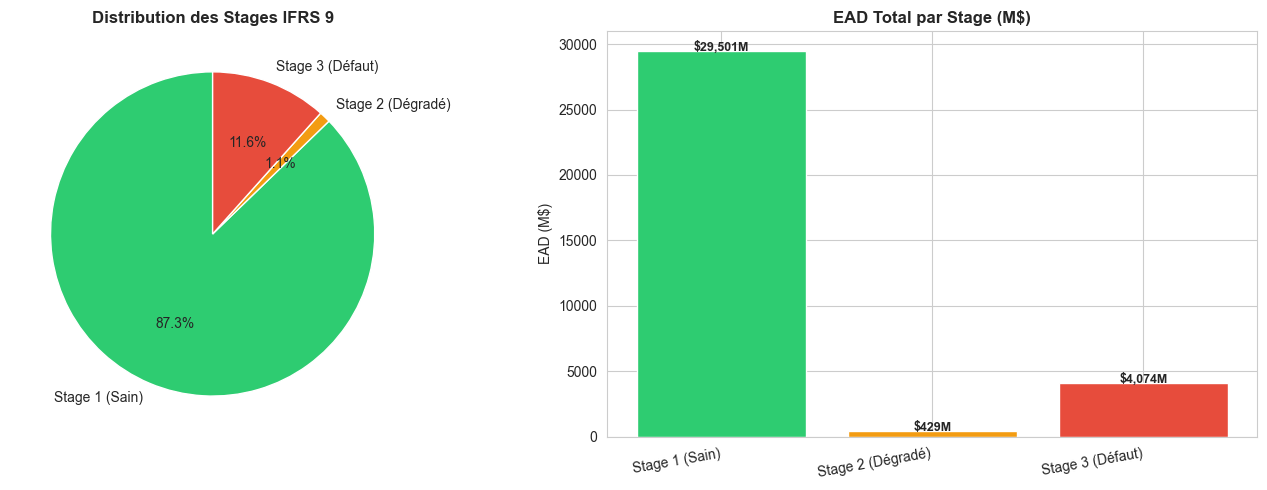

In [6]:
print('=== Distribution des Stages IFRS 9 ===')
stage_dist = df['stage'].value_counts().sort_index()
stage_labels = {1: 'Stage 1 (Sain)', 2: 'Stage 2 (Dégradé)', 3: 'Stage 3 (Défaut)'}
stage_colors = ['#2ecc71', '#f39c12', '#e74c3c']

for s, n in stage_dist.items():
    print(f'  {stage_labels.get(s, s):25s} : {n:>10,} ({n/len(df):.2%})')

print(f'\nEAD total                  : ${df["EAD"].sum()/1e9:.2f} Mrd')
print(f'EAD Stage 1                : ${df[df["stage"]==1]["EAD"].sum()/1e9:.2f} Mrd ({df[df["stage"]==1]["EAD"].sum()/df["EAD"].sum():.1%})')
print(f'EAD Stage 2+3              : ${df[df["stage"]>1]["EAD"].sum()/1e9:.2f} Mrd ({df[df["stage"]>1]["EAD"].sum()/df["EAD"].sum():.1%})')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].pie([stage_dist.get(s, 0) for s in [1,2,3]],
            labels=[stage_labels[s] for s in [1,2,3]],
            autopct='%1.1f%%', colors=stage_colors, startangle=90)
axes[0].set_title('Distribution des Stages IFRS 9', fontweight='bold')

ecl_by_stage = df.groupby('stage').agg(
    EAD_M=('EAD', lambda x: x.sum()/1e6),
    LGD_moy=('LGD', 'mean'),
    nb_prets=('EAD', 'count')
)
ecl_by_stage.index = [stage_labels.get(s, s) for s in ecl_by_stage.index]

x = range(len(ecl_by_stage))
bars = axes[1].bar(x, ecl_by_stage['EAD_M'], color=stage_colors, edgecolor='white')
axes[1].set_xticks(x)
axes[1].set_xticklabels(ecl_by_stage.index, rotation=10, ha='right')
axes[1].set_title('EAD Total par Stage (M$)', fontweight='bold')
axes[1].set_ylabel('EAD (M$)')
for bar, v in zip(bars, ecl_by_stage['EAD_M']):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
                 f'${v:,.0f}M', ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_12_stages_ifrs9.png', dpi=150, bbox_inches='tight')
plt.show()


---
## 4. Validation LGD & EAD


=== LGD par Grade — Validation Monotonie ===
                                                       grade   mean  median  \
grade_num                                                                     
1          AAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAA...  52.43   52.43   
2          BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB...  56.12   56.12   
3          CCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCC...  61.27   61.27   
4          DDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDD...  64.94   64.94   
5          EEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEE...  68.84   68.84   
6          FFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFF...  72.28   72.28   
7          GGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGG...  75.72   75.72   

             std  
grade_num         
1           4.32  
2           6.27  
3           7.62  
4           8.86  
5           9.75  
6          10.74  
7          10.34  

Monotonie LGD (A<B<...<G) : OK


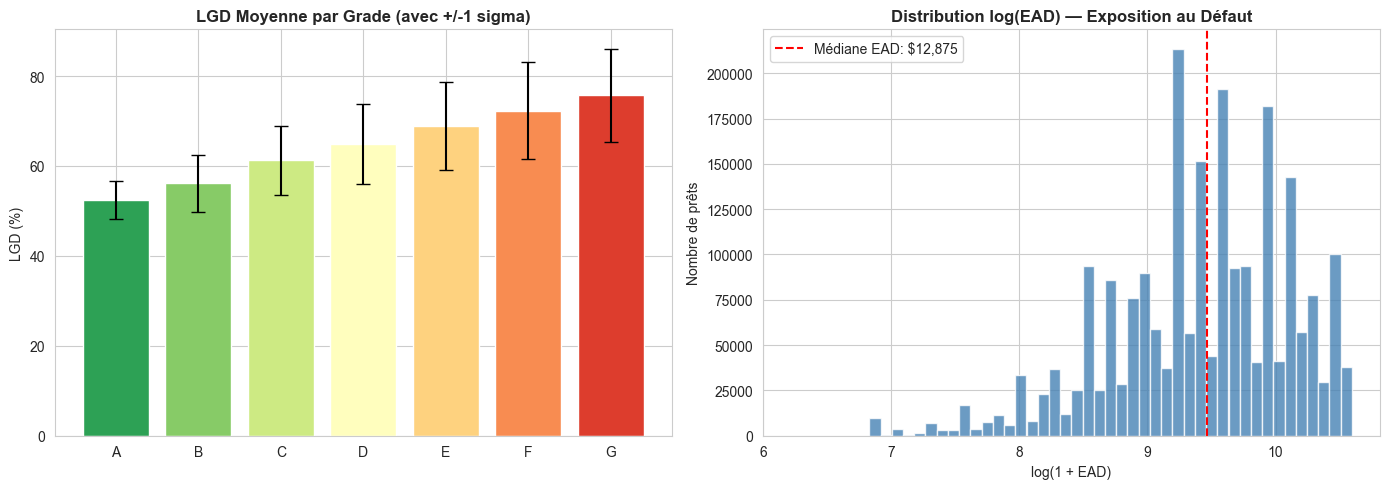

In [7]:
# Validation LGD : doit être croissante avec le grade (A→G)
print('=== LGD par Grade — Validation Monotonie ===')
lgd_by_grade = df.groupby('grade_num')['LGD'].agg(['mean', 'median', 'std'])
lgd_by_grade.index.name = 'grade_num'
grade_names = {1:'A', 2:'B', 3:'C', 4:'D', 5:'E', 6:'F', 7:'G'}
lgd_by_grade['grade'] = lgd_by_grade.index.map(grade_names)
print((lgd_by_grade[['grade', 'mean', 'median', 'std']] * 100).round(2))

monotone = (lgd_by_grade['mean'].diff().dropna() > 0).all()
print(f'\nMonotonie LGD (A<B<...<G) : {"OK" if monotone else "ATTENTION — non monotone"}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# LGD par grade
grade_labels = [grade_names.get(i, str(i)) for i in lgd_by_grade.index]
x = range(len(lgd_by_grade))
axes[0].bar(x, lgd_by_grade['mean'] * 100, color=PALETTE, edgecolor='white')
axes[0].errorbar(x, lgd_by_grade['mean'] * 100, yerr=lgd_by_grade['std'] * 100,
                  fmt='none', color='black', capsize=5)
axes[0].set_xticks(x)
axes[0].set_xticklabels(grade_labels)
axes[0].set_title('LGD Moyenne par Grade (avec +/-1 sigma)', fontweight='bold')
axes[0].set_ylabel('LGD (%)')

# EAD distribution
ead_positive = df['EAD'][df['EAD'] > 0]
axes[1].hist(np.log1p(ead_positive), bins=50, color='steelblue', edgecolor='white', alpha=0.8)
axes[1].set_title('Distribution log(EAD) — Exposition au Défaut', fontweight='bold')
axes[1].set_xlabel('log(1 + EAD)')
axes[1].set_ylabel('Nombre de prêts')
axes[1].axvline(np.log1p(ead_positive.median()), color='red', linestyle='--',
                label=f'Médiane EAD: ${ead_positive.median():,.0f}')
axes[1].legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_13_lgd_ead_validation.png', dpi=150, bbox_inches='tight')
plt.show()


---
## 5. Confirmation de la sauvegarde


In [8]:
# Vérification du fichier Parquet
parquet_path = OUTPUT_DIR / 'loan_clean.parquet'

if parquet_path.exists():
    size_mb = parquet_path.stat().st_size / 1e6
    df_check = pd.read_parquet(parquet_path)
    print(f'=== Fichier Parquet validé ===')
    print(f'Chemin   : {parquet_path}')
    print(f'Taille   : {size_mb:.1f} Mo')
    print(f'Lignes   : {len(df_check):,}')
    print(f'Colonnes : {df_check.shape[1]}')
    print(f'Colonnes : {list(df_check.columns)}')
    print(f'\nAperçu :')
    display(df_check.head(3))
else:
    print('ERREUR : le fichier Parquet n\'a pas été créé.')
    print('Vérifiez que le pipeline a été exécuté sans erreur.')


=== Fichier Parquet validé ===
Chemin   : ..\outputs\loan_clean.parquet
Taille   : 41.7 Mo
Lignes   : 2,260,668
Colonnes : 35
Colonnes : ['loan_amnt', 'grade', 'issue_d', 'term_months', 'vintage_year', 'vintage_quarter', 'observation_months', 'mature_12m_flag', 'mature_24m_flag', 'grade_num', 'subgrade_num', 'dti', 'revol_util', 'int_rate', 'delinq_2yrs', 'log_annual_inc', 'credit_age_months', 'pub_rec', 'open_acc', 'emp_length_num', 'verif_status_num', 'ho_RENT', 'ho_OWN', 'UNRATE', 'GDPC1_growth', 'FEDFUNDS', 'HY_SPREAD', 'CPI_change', 'DRCCLACBS', 'default_flag', 'default_12m_observed', 'default_24m_observed', 'stage', 'LGD', 'EAD']

Aperçu :


,loan_amnt,grade,issue_d,term_months,vintage_year,vintage_quarter,observation_months,mature_12m_flag,mature_24m_flag,grade_num,...,FEDFUNDS,HY_SPREAD,CPI_change,DRCCLACBS,default_flag,default_12m_observed,default_24m_observed,stage,LGD,EAD
0,2500,C,2018-12-01,36.0,2018,2018Q4,2.036961,0,0,3,...,2.27,4.7635,2.002381,2.54,0,NaN,NaN,1,0.612705,2500
1,30000,D,2018-12-01,60.0,2018,2018Q4,2.036961,0,0,4,...,2.27,4.7635,2.002381,2.54,0,NaN,NaN,1,0.649445,30000
2,5000,D,2018-12-01,36.0,2018,2018Q4,2.036961,0,0,4,...,2.27,4.7635,2.002381,2.54,0,NaN,NaN,1,0.649445,5000


In [9]:
# Résumé final
print('\n' + '='*55)
print('RÉSUMÉ — Notebook 02 Preprocessing terminé')
print('='*55)
print(f'  Dataset : {len(df_check):,} prêts x {df_check.shape[1]} colonnes')
print(f'  Parquet : {parquet_path.name} ({size_mb:.1f} Mo)')
print(f'  Taux de défaut : {df_check["default_flag"].mean():.2%}')
stage_counts = df_check['stage'].value_counts().sort_index()
for s, n in stage_counts.items():
    print(f'  Stage {s} : {n:,} prêts ({n/len(df_check):.1%})')
print(f'  LGD médiane : {df_check["LGD"].median():.2%}')
print(f'  EAD total   : ${df_check["EAD"].sum()/1e9:.2f} Mrd')
print('='*55)
print('\nProchain notebook : 03_Baseline_ECL.ipynb')



RÉSUMÉ — Notebook 02 Preprocessing terminé
  Dataset : 2,260,668 prêts x 35 colonnes
  Parquet : loan_clean.parquet (41.7 Mo)
  Taux de défaut : 11.61%
  Stage 1 : 1,972,587 prêts (87.3%)
  Stage 2 : 25,634 prêts (1.1%)
  Stage 3 : 262,447 prêts (11.6%)
  LGD médiane : 58.96%
  EAD total   : $34.00 Mrd

Prochain notebook : 03_Baseline_ECL.ipynb


## Coherence avec la chaine IFRS 9 + Bale + stress testing

Ce notebook s'inscrit dans la chaine complete:

`Donnees -> Qualite -> PD/LGD/EAD -> ECL IFRS 9 -> Satellites macro -> Stress Y1 -> RWA/CET1 -> Decision -> Gouvernance`

Les resultats finaux de niveau bancaire sont consolides dans:

- `notebooks/08_Banking_Expert_Review.ipynb`
- `outputs/results/one_year_stress_decision_matrix.csv`
- `outputs/results/basel_capital_metrics.csv`
- `outputs/results/regulatory_segment_summary.csv`
- `outputs/results/dynamic_projection_expert.csv`

Cette coherence permet de defendre le projet a la fois comme travail de modelisation
et comme prototype de plateforme bancaire.